# CS-781 Capstone, Phase 1, Attempt 3: Mamba-2 / Attention Hybrid Language Model (from scratch)

Architecture #3 of the required four (#1 decoder-only transformer, #2 encoder-decoder transformer).

## ADR-003: A state-space / attention hybrid for the Phase-1 legal LM

**Status:** Accepted  |  **Date:** 2026-10-06  |  **Deciders:** project owner (to be defended at the viva)

### Context
* **Hard constraints:** free Kaggle T4 (fp16 only, no bf16, no fused attention or SSM kernels, so everything is plain PyTorch); 50M-300M parameters; trained from scratch on about 150M tokens; the output is a 128-word continuation of a 512-word prompt, scored mainly by BERTScore F1.
* **Portfolio constraint:** the assignment needs at least four *structurally* different architectures. Attempts 1 and 2 are both softmax-attention transformers.
* **What the task rewards:** (a) topical, stylistic and structural continuation, which depends on a compressed summary of the prompt and on the recent text, and (b) re-using exact entities from the prompt (parties, statute numbers, court names), which needs precise recall of earlier tokens.
* **Efficiency reality check:** prompt plus output is only about 800 tokens (a 512-word prompt is ~610 tokens with our BPE, 128 words are ~165), so attention's O(n^2) cost is *not* the bottleneck here. The real efficiency levers are the size of the decoding state and the number of attention layers, not asymptotics.

### Decision
A **decoder-only hybrid** of 18 **Mamba-2 (SSD) layers** and 6 **grouped-query attention + SwiGLU layers**, in the repeating pattern `MMMA` (128M parameters). It is trained exactly like attempt 1 (next-token prediction on packed blocks), so data, tokenizer, validation set and submission code are shared.

### Options considered
| Option | Complexity | T4 / pure-PyTorch feasibility | Fit to this task | Different from #1 and #2? |
|---|---|---|---|---|
| A. Pure Mamba-2 (no attention) | Med | Good (SSD is matmul-based) | Weaker at exact copy/recall from the prompt | Very |
| **B. Mamba-2 + attention hybrid (chosen)** | Med-High | Good | Best of both: compressed context in SSM layers, exact recall in attention layers | Very (75% of layers have no attention, no positional encoding, constant-size state) |
| C. RetNet / gated linear attention | Med | Good, but weaker numerics in fp16 | Fixed-size state, same copy weakness as A, and generally weaker than Mamba-2 | Yes |
| D. RWKV-6/7 | High | Poor: needs custom CUDA kernels for speed | Similar to A | Yes |
| E. MLA + MoE decoder | High | Medium (routing overhead) | Same softmax-attention family | No (still a transformer) |
| F. Sliding-window / local-attention transformer | Low | Good | Context is only ~1k tokens, so little to gain | No |

### Trade-off analysis
* **A vs B:** pure SSMs compress the prompt into a fixed-size state, and are known to be worse than transformers at verbatim copying or retrieval from context. Legal text repeats party names and section numbers constantly, so a few attention layers are cheap insurance (they are only 6 of 24 layers, and use GQA so their cache is small).
* **B vs C/D:** Mamba-2's SSD form is chunked matrix multiplication, which maps onto tensor cores in plain PyTorch; RWKV/RetNet-style kernels either need custom CUDA or are less stable in fp16.
* **B vs E/F:** both remain softmax-attention transformers, so they would not count as a substantially different fourth architecture.

### Consequences
* **Easier:** decoding memory per sequence is smaller and *independent of prompt length* for 18 of 24 layers (see the printout below); batched generation is cheap; there is no positional encoding in the SSM layers.
* **Harder:** training in pure PyTorch is probably *slower per token* than attention with fused kernels, because the SSD scan is many small ops. The efficiency claim here is about **inference state and decode cost**, not training speed. The benchmark cell measures this and auto-fits the token budget to your session.
* **Different downstream story:** like attempt 1 this is a causal model, so Phases 2-5 would use pooled hidden states; the encoder-decoder (attempt 2) stays the stronger starting point for encoder-style tasks.
* **To revisit:** the attention ratio (`PATTERN`), the state size `D_STATE`, and a pure-SSM ablation (`PATTERN = "M" * 30`, 135M parameters).

### Action items
1. [ ] Run the correctness checks and the throughput benchmark (cells below) before training.
2. [ ] Train, then compare against attempts 1 and 2 on the *same* local prompts (BERTScore F1 and ROUGE-L).
3. [ ] Ablate the pattern (pure `M`, and `MMMMMMMA`) to justify the 1-in-4 attention ratio.

*Background (cited from memory, no search access, so please verify before citing in a report): the Mamba-2 / state-space duality paper (Dao and Gu, 2024), and the hybrid designs Jamba, Zamba and Samba, which report that mixing a few attention layers into SSM stacks beats pure SSMs; "Repeat After Me" (Jelassi et al., 2024) on the copying weakness of fixed-state models.*

## What the model does
```
tokens -> embedding -> [ M M M A ] x 6 -> RMSNorm -> tied output head
M = RMSNorm -> Mamba-2 block (in_proj -> causal conv -> selective SSM via chunked SSD -> gated RMSNorm -> out_proj) + residual
A = RMSNorm -> GQA attention (RoPE) + residual -> RMSNorm -> SwiGLU + residual
```
Training uses the *parallel* (chunked) form. Generation reads the prompt once in parallel form (left-padded, with padding made exactly invisible to the SSM), then decodes with the *recurrent* form (constant time and memory per token in the SSM layers).

## 1. Configuration

In [1]:
import os, sys, json, re, math, time, zlib, hashlib, random, zipfile, heapq, subprocess, shutil
from collections import Counter, defaultdict
from dataclasses import dataclass
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.utils.checkpoint

DEBUG = False            # True = tiny end-to-end smoke test (minutes, not hours)
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"
OUTPUT_DIR = "/kaggle/working/cs781_phase1_hybrid"      # checkpoints, predictions, submission
# To skip re-building the corpus / tokenizer / packed bins, point REUSE_DIR at the attempt-1 (or attempt-2) output
# folder (it must contain train_*.jsonl, val.jsonl, bpe_merges.json, train.bin, val.bin, corpus_stats.json),
# e.g. a Kaggle dataset: REUSE_DIR = "/kaggle/input/<your-dataset>/cs781_phase1"
REUSE_DIR = None
DATA_DIR = REUSE_DIR or OUTPUT_DIR
os.makedirs(OUTPUT_DIR, exist_ok=True); os.makedirs(DATA_DIR, exist_ok=True)
PREDICTION_PATH = f"{OUTPUT_DIR}/prediction.json"
SUBMISSION_ZIP = f"{OUTPUT_DIR}/submission.zip"

# --- Data plan: IDENTICAL to attempts 1 and 2 ---
SOURCES = {
    "supreme_court": ("train_supreme_court.json", 0.50, 66_000_000, 200),
    "high_courts":   ("train_high_courts.json",   0.05, 27_000_000, 200),
    "tribunals":     ("train_tribunals.json",     0.15,  8_000_000, 200),
    "acts":          ("train_acts.json",          1.00,  9_000_000,  50),
}
MAX_WORDS_PER_DOC = 8_000
VAL_MOD = 100

# --- Tokenizer: IDENTICAL to attempts 1 and 2 ---
VOCAB_SIZE = 32_000
TOKENIZER_CHARS_PER_SOURCE = 40_000_000
TOKENIZER_MIN_WORD_FREQ = 3

# --- Hybrid model (about 128M parameters at these settings) ---
CONTEXT = 1280                   # training block length (same as attempt 1)
D_MODEL = 768
PATTERN = "MMMA" * 5             # M = Mamba-2 layer, A = attention+SwiGLU layer. "M"*30 = pure SSM ablation
EXPAND, HEADDIM, D_STATE, D_CONV = 2, 64, 64, 4     # SSM: d_inner = 2*768 = 1536 -> 24 heads of size 64, state 64
SSD_CHUNK = 64                   # SSD chunk length (memory grows linearly with it)
N_HEAD, N_KV_HEAD, N_FFN = 12, 4, 2048              # attention layers (GQA) and their SwiGLU
GRAD_CKPT = False                # True trades ~30% speed for much lower memory
USE_COMPILE = False              # torch.compile can fuse the many small SSD ops (untested on T4; try after a clean run)

# --- Optimisation ---
MICRO_BS, GRAD_ACCUM = 4, 16     # 4*16*1280 = ~82k tokens per optimizer step (same as attempt 1)
LR, MIN_LR, WEIGHT_DECAY, WARMUP_FRAC = 6e-4, 6e-5, 0.1, 0.03
EVAL_EVERY, EVAL_BATCHES, LOG_EVERY = 200, 60, 20
MAX_TRAIN_HOURS = 10.0           # safety stop for Kaggle's session limit; resume afterwards
MAX_STEPS = 1076                 # None = one full epoch. The benchmark cell can set this to fit your time budget
AUTO_FIT_BUDGET, TARGET_TRAIN_HOURS = True, 8.0
PLAN_PATH = f"{OUTPUT_DIR}/run_plan.json"          # remembers MAX_STEPS so resumed sessions keep the same LR schedule

# --- Validation window that mimics the test task (same as attempt 2): 610-token prompt (test median) -> next 192 tokens ---
VAL_ENC, VAL_DEC = 610, 192

# --- Generation ---
PROMPT_WORDS, TARGET_WORDS = 512, 128
MAX_NEW_TOKENS = 256
EOS_PLACEHOLDER = "<|endoftext|>"
USE_BERTSCORE = True             # primary competition metric; falls back to ROUGE-L if unavailable

if DEBUG:
    SOURCES = {k: (v[0], 1.0, 300_000, v[3]) for k, v in SOURCES.items()}
    VOCAB_SIZE, TOKENIZER_CHARS_PER_SOURCE, TOKENIZER_MIN_WORD_FREQ = 4_000, 2_000_000, 2
    CONTEXT, D_MODEL, PATTERN, HEADDIM, D_STATE, SSD_CHUNK = 256, 128, "MMMA", 32, 16, 32
    N_HEAD, N_KV_HEAD, N_FFN = 4, 2, 352
    VAL_ENC, VAL_DEC = 128, 64
    EVAL_EVERY, EVAL_BATCHES, LOG_EVERY, MICRO_BS, GRAD_ACCUM = 20, 5, 5, 8, 2
    MAX_NEW_TOKENS = 64
    VAL_MOD = 10

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device, "|", torch.cuda.get_device_name(0) if device == "cuda" else "")

device: cuda | Tesla T4


## 2. Access the dataset and inspect the test prompts
(unchanged from attempt 1)

In [2]:
from huggingface_hub import HfApi, hf_hub_download, login

try:
    from kaggle_secrets import UserSecretsClient
    HF_TOKEN = UserSecretsClient().get_secret("capstone-phase1-token")
    os.environ["HF_TOKEN"] = HF_TOKEN
    login(token=HF_TOKEN)
except Exception:
    HF_TOKEN = os.environ.get("HF_TOKEN")

_repo_files = HfApi().list_repo_files(HF_DATASET_REPO, repo_type="dataset", token=HF_TOKEN)

def fetch(*must_contain):
    """Find a repo file whose path contains all given substrings (case-insensitive)."""
    hits = [f for f in _repo_files if all(s.lower() in f.lower() for s in must_contain)]
    if not hits:
        raise FileNotFoundError(f"{must_contain} not found. Repo has: {_repo_files[:40]}")
    return hf_hub_download(HF_DATASET_REPO, hits[0], repo_type="dataset", token=HF_TOKEN)

test_path = fetch("phase_1", "test", ".json")
with open(test_path, encoding="utf-8") as f:
    test_data = json.load(f)
test_prompts_raw = [v["text"] for v in test_data.values()]
frac_nl = np.mean(["\n" in p for p in test_prompts_raw])
KEEP_NEWLINES = bool(frac_nl > 0.5)
print(f"test prompts: {len(test_prompts_raw)} | with newlines: {frac_nl:.0%} "
      f"| median words: {np.median([len(p.split()) for p in test_prompts_raw]):.0f}")
print("KEEP_NEWLINES =", KEEP_NEWLINES, "(training text is formatted to match the test prompts)")

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


test.json:   0%|          | 0.00/3.03M [00:00<?, ?B/s]

test prompts: 1000 | with newlines: 0% | median words: 512
KEEP_NEWLINES = False (training text is formatted to match the test prompts)


In [3]:
test_prompts_raw[1]

'Instead of taking cognizance of the offence, he has, in the exercise of his discretion, sent the complaint for investigation by police under Section 156." 12) In Tula Ram & Ors. vs. Kishore Singh (supra) again this Court considered order for investigation under [Section 2] 156 (3) on a complaint. After considering various earlier decisions, the Court on a careful consideration of the facts and circumstances of the case propounded the following legal propositions:- ".... 1. That a Magistrate can order investigation under [S. 156 (3)] only at the pre-cognizance stage, that is to say, before taking cognizance under Sections 190, 200 and 204 and where a Magistrate decides to take cognizance under the provisions of Chapter 14 he is not entitled in law to order any investigation under Section 156 (3) though in cases not falling within the proviso to Section 202 he can order an investigation by the police which would be in the nature of an enquiry as contemplated by Sec. 202 of the Code. 2. 

## 3. Cleaning rules for Indian legal text
(unchanged from attempt 1)

In [4]:
BOILERPLATE = [
    re.compile(r"^\s*page\s+\d+(\s+of\s+\d+)?\s*$", re.I),
    re.compile(r"^\s*-?\s*\d{1,4}\s*-?\s*$"),                          # bare page numbers
    re.compile(r"^\s*(https?://|www\.)\S+\s*$", re.I),
    re.compile(r"^\s*(indian\s*kanoon|manupatra|scc\s*online|supreme\s*court\s*cases)\b.*$", re.I),
    re.compile(r"^\s*(digitally\s+signed\s+by|signature\s+not\s+verified|reason:|location:)\b.*$", re.I),
    re.compile(r"^\s*(reportable|non-?reportable)\s*$", re.I),
]
CHAR_MAP = str.maketrans({
    "\u2018": "'", "\u2019": "'", "\u201c": '"', "\u201d": '"', "\u2013": "-", "\u2014": "-",
    "\u2212": "-", "\u2026": "...", "\u00a0": " ", "\u200b": "", "\ufeff": "", "\u00ad": "",
})
CTRL = re.compile(r"[\x00-\x08\x0b\x0c\x0e-\x1f\x7f]")

def normalize_text(t: str, keep_newlines: bool) -> str:
    """Character and whitespace normalisation. Applied to train text AND test prompts."""
    t = CTRL.sub(" ", t.translate(CHAR_MAP))
    if keep_newlines:
        t = re.sub(r"[ \t]+", " ", t)
        t = re.sub(r" ?\n ?", "\n", t)
        t = re.sub(r"\n{3,}", "\n\n", t)
    else:
        t = re.sub(r"\s+", " ", t)
    return t.strip()

def clean_document(t: str, keep_newlines: bool) -> str:
    kept = [l for l in t.splitlines() if not any(p.match(l) for p in BOILERPLATE)]
    return normalize_text("\n".join(kept), keep_newlines)

def passes_quality(text: str, min_words: int):
    """Returns (ok, reason)."""
    if len(text.split()) < min_words:
        return False, "too_short"
    sample = text[:20_000]
    n = max(len(sample), 1)
    if sum(c.isalpha() for c in sample) / n < 0.60:
        return False, "low_alpha"             # OCR garbage, number tables
    if sum(ord(c) < 128 for c in sample) / n < 0.90:
        return False, "non_english"
    lines = [l.strip() for l in text.split("\n") if l.strip()]
    if len(lines) > 20 and len(set(lines)) / len(lines) < 0.30:
        return False, "repetitive"
    return True, ""

def stream_records(path):
    """Stream a (possibly multi-GB) JSON array without loading it into RAM."""
    try:
        import ijson
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ijson"], check=False)
        import ijson
    with open(path, "rb") as f:
        for rec in ijson.items(f, "item"):
            yield rec

## 4. Stage A: stream, clean, deduplicate, split by document
(unchanged; skipped automatically if the corpus already exists in `DATA_DIR`)

In [5]:
def build_corpus():
    seen, all_stats = set(), {}
    val_f = open(f"{DATA_DIR}/val.jsonl", "w", encoding="utf-8")
    for src, (fname, keep_p, budget, min_words) in SOURCES.items():
        path = fetch(fname)
        out = open(f"{DATA_DIR}/train_{src}.jsonl", "w", encoding="utf-8")
        rng = random.Random(SEED)
        st = Counter(); words_kept = 0; t0 = time.time()
        for rec in stream_records(path):
            st["seen"] += 1
            if rng.random() > keep_p:
                continue
            text = clean_document(rec["text"] if isinstance(rec, dict) else str(rec), KEEP_NEWLINES)
            ok, why = passes_quality(text, min_words)
            if not ok:
                st["drop_" + why] += 1; continue
            fp = hashlib.md5(re.sub(r"\W+", "", text[:3000].lower()).encode()).hexdigest()
            if fp in seen:
                st["drop_duplicate"] += 1; continue
            seen.add(fp)
            words = text.split()
            if len(words) > MAX_WORDS_PER_DOC:
                text = " ".join(words[:MAX_WORDS_PER_DOC]); st["truncated"] += 1
                words = words[:MAX_WORDS_PER_DOC]
            row = json.dumps({"src": src, "text": text}, ensure_ascii=False) + "\n"
            if zlib.crc32(fp.encode()) % VAL_MOD == 0:
                val_f.write(row); st["val_docs"] += 1
            else:
                out.write(row); st["train_docs"] += 1
            words_kept += len(words)
            if words_kept >= budget:
                break
        out.close()
        st["words"] = words_kept; st["minutes"] = round((time.time() - t0) / 60, 1)
        all_stats[src] = dict(st)
        flag = "" if words_kept >= 0.95 * budget else "  <-- UNDER BUDGET: raise keep-probability"
        print(f"{src:14s} {dict(st)}{flag}")
    val_f.close()
    json.dump(all_stats, open(f"{DATA_DIR}/corpus_stats.json", "w"), indent=2)

if not os.path.exists(f"{DATA_DIR}/val.jsonl"):
    build_corpus()
else:
    print("corpus already built:", open(f"{DATA_DIR}/corpus_stats.json").read()[:600])

Phase_1_Pretraining/Train/train_supreme_(…): reconstructing file:   0%|          |  0.00B / 1.32GB            

Phase_1_Pretraining/Train/train_supreme_(…): downloading bytes:           |  0.00B            

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 149.9/149.9 kB 5.8 MB/s eta 0:00:00
supreme_court  {'seen': 43063, 'train_docs': 20705, 'truncated': 2033, 'val_docs': 235, 'drop_too_short': 616, 'drop_low_alpha': 13, 'drop_duplicate': 23, 'drop_non_english': 1, 'words': 66003826, 'minutes': 1.8}


Phase_1_Pretraining/Train/train_high_cou(…): reconstructing file:   0%|          |  0.00B / 10.7GB            

Phase_1_Pretraining/Train/train_high_cou(…): downloading bytes:           |  0.00B            

high_courts    {'seen': 1079597, 'drop_too_short': 19671, 'train_docs': 32707, 'val_docs': 344, 'truncated': 262, 'drop_low_alpha': 256, 'drop_duplicate': 898, 'words': 27000462, 'minutes': 1.1}


... (2 outputs left out)

tribunals      {'seen': 31934, 'train_docs': 4506, 'truncated': 157, 'drop_too_short': 270, 'val_docs': 41, 'drop_low_alpha': 3, 'words': 8000161, 'minutes': 0.2}


Phase_1_Pretraining/Train/train_acts.jso(…): reconstructing file:   0%|          |  0.00B /  729MB            

Phase_1_Pretraining/Train/train_acts.jso(…): downloading bytes:           |  0.00B            

acts           {'seen': 2622, 'train_docs': 2577, 'truncated': 467, 'val_docs': 29, 'drop_low_alpha': 12, 'drop_too_short': 1, 'drop_duplicate': 3, 'words': 9001700, 'minutes': 0.3}


## 5. Byte-level BPE tokenizer, implemented from scratch
(unchanged; the saved merges are reused if present in `DATA_DIR`)

In [6]:
PRETOKEN_RE = re.compile(r"""'(?:[sdmt]|ll|ve|re)| ?[^\W\d_]+| ?\d{1,3}| ?(?:[^\s\w]|_)+|\s+(?!\S)|\s+""")

class ByteBPE:
    def __init__(self, merges=None):
        self.merges = [tuple(m) for m in (merges or [])]
        self.rank = {p: i for i, p in enumerate(self.merges)}
        self.vocab = [bytes([i]) for i in range(256)]
        for a, b in self.merges:
            self.vocab.append(self.vocab[a] + self.vocab[b])
        self.eos_id = len(self.vocab)
        self.vocab.append(EOS_PLACEHOLDER.encode())
        self.vocab_size = len(self.vocab)
        self._cache = {}

    # ---------- training ----------
    @staticmethod
    def train(chunk_counts, vocab_size, min_freq=3, log_every=2000):
        n_merges = vocab_size - 256 - 1                      # last id is EOS
        items = [(c.encode("utf-8"), f) for c, f in chunk_counts.items() if f >= min_freq]
        words = [list(b) for b, _ in items]
        freqs = [f for _, f in items]
        pair_cnt, where = defaultdict(int), defaultdict(set)
        for i, w in enumerate(words):
            for p in zip(w, w[1:]):
                pair_cnt[p] += freqs[i]; where[p].add(i)
        heap = [(-c, p) for p, c in pair_cnt.items()]
        heapq.heapify(heap)
        merges, t0 = [], time.time()
        while len(merges) < n_merges:
            best = None
            while heap:                                       # lazy deletion
                negc, p = heapq.heappop(heap)
                c = pair_cnt.get(p, 0)
                if c <= 0: continue
                if c != -negc:
                    heapq.heappush(heap, (-c, p)); continue
                best = p; break
            if best is None: break
            a, b = best; new_id = 256 + len(merges); merges.append(best)
            changed = set()
            for i in list(where[best]):
                w, f = words[i], freqs[i]
                out, j, n, hit = [], 0, len(w), False
                while j < n:
                    if j < n - 1 and w[j] == a and w[j + 1] == b:
                        out.append(new_id); j += 2; hit = True
                    else:
                        out.append(w[j]); j += 1
                if not hit: continue
                for q in zip(w, w[1:]): pair_cnt[q] -= f
                for q in zip(out, out[1:]):
                    pair_cnt[q] += f; where[q].add(i); changed.add(q)
                words[i] = out
            where.pop(best, None); pair_cnt.pop(best, None)
            for q in changed:
                if pair_cnt[q] > 0: heapq.heappush(heap, (-pair_cnt[q], q))
            if len(merges) % log_every == 0:
                print(f"  merges {len(merges):6d}/{n_merges} | {time.time() - t0:5.0f}s")
        return ByteBPE(merges)

    # ---------- encoding / decoding ----------
    def _encode_chunk(self, chunk):
        hit = self._cache.get(chunk)
        if hit is not None: return hit
        ids = list(chunk.encode("utf-8"))
        while len(ids) > 1:
            best_r, best_p = None, None
            for p in zip(ids, ids[1:]):
                r = self.rank.get(p)
                if r is not None and (best_r is None or r < best_r):
                    best_r, best_p = r, p
            if best_p is None: break
            a, b = best_p; new_id = 256 + best_r; out, j = [], 0
            while j < len(ids):
                if j < len(ids) - 1 and ids[j] == a and ids[j + 1] == b:
                    out.append(new_id); j += 2
                else:
                    out.append(ids[j]); j += 1
            ids = out
        if len(self._cache) > 3_000_000: self._cache.clear()
        self._cache[chunk] = ids
        return ids

    def encode(self, text):
        ids = []
        for chunk in PRETOKEN_RE.findall(text):
            ids.extend(self._encode_chunk(chunk))
        return ids

    def decode(self, ids):
        data = b"".join(self.vocab[i] for i in ids if i != self.eos_id)
        return data.decode("utf-8", errors="replace")

    def save(self, path):
        json.dump({"merges": self.merges, "eos": EOS_PLACEHOLDER}, open(path, "w"))

    @staticmethod
    def load(path):
        return ByteBPE(json.load(open(path))["merges"])

In [7]:
TOK_PATH = f"{DATA_DIR}/bpe_merges.json"

def count_chunks():
    counts = Counter()
    for src in SOURCES:
        used = 0
        with open(f"{DATA_DIR}/train_{src}.jsonl", encoding="utf-8") as f:
            for line in f:
                t = json.loads(line)["text"]
                counts.update(PRETOKEN_RE.findall(t))
                used += len(t)
                if used >= TOKENIZER_CHARS_PER_SOURCE: break
        print(f"  counted {src}: {len(counts):,} unique pre-tokens so far")
    return counts

if not os.path.exists(TOK_PATH):
    t0 = time.time()
    tokenizer = ByteBPE.train(count_chunks(), VOCAB_SIZE, TOKENIZER_MIN_WORD_FREQ)
    tokenizer.save(TOK_PATH)
    print(f"tokenizer trained in {(time.time() - t0) / 60:.1f} min")
tokenizer = ByteBPE.load(TOK_PATH)
EOS_ID = tokenizer.eos_id
print("vocab size:", tokenizer.vocab_size)

# sanity: lossless round-trip on awkward strings
for s in ["Section 302 IPC read with 34; (2011) 4 SCC 1.\n\nHeld: appeal dismissed.",
          "caf\u00e9 \u20b95,00,000 \u2014 unicode & ____ 123456789"]:
    assert tokenizer.decode(tokenizer.encode(s)) == s, "round-trip failed"
print("round-trip OK | sample:", [tokenizer.vocab[i].decode("utf-8", "replace")
      for i in tokenizer.encode("The appellant filed a Special Leave Petition under Article 136.")])
if DATA_DIR != OUTPUT_DIR:
    shutil.copy(TOK_PATH, f"{OUTPUT_DIR}/bpe_merges.json")   # keep a copy next to the model checkpoints

  counted supreme_court: 75,745 unique pre-tokens so far
  counted high_courts: 110,530 unique pre-tokens so far
  counted tribunals: 138,794 unique pre-tokens so far
  counted acts: 166,073 unique pre-tokens so far
  merges   2000/31743 |     3s
  merges   4000/31743 |     4s
  merges   6000/31743 |     4s
  merges   8000/31743 |     4s
  merges  10000/31743 |     4s
  merges  12000/31743 |     5s
  merges  14000/31743 |     5s
  merges  16000/31743 |     5s
  merges  18000/31743 |     5s
  merges  20000/31743 |     5s
  merges  22000/31743 |     5s
  merges  24000/31743 |     5s
  merges  26000/31743 |     5s
  merges  28000/31743 |     5s
  merges  30000/31743 |     5s
tokenizer trained in 0.3 min
vocab size: 32000
round-trip OK | sample: ['The', ' appellant', ' filed', ' a', ' Special', ' Leave', ' Petition', ' under', ' Article', ' 136', '.']


## 6. Stage B: tokenise and pack
(unchanged from attempt 1: one `uint16` memmap, documents joined by EOS)

In [8]:
def pack_to_bin(jsonl_paths, out_path):
    n_tok = n_words = 0
    with open(out_path, "wb") as out:
        for jp in jsonl_paths:
            buf = []
            with open(jp, encoding="utf-8") as f:
                for line in f:
                    text = json.loads(line)["text"]
                    n_words += len(text.split())
                    ids = tokenizer.encode(text); ids.append(EOS_ID)
                    buf.append(np.asarray(ids, dtype=np.uint16))
                    if len(buf) >= 2000:
                        arr = np.concatenate(buf); arr.tofile(out); n_tok += len(arr); buf = []
            if buf:
                arr = np.concatenate(buf); arr.tofile(out); n_tok += len(arr)
            print(f"  packed {os.path.basename(jp)}: running total {n_tok:,} tokens")
    return n_tok, n_words

TRAIN_BIN, VAL_BIN = f"{DATA_DIR}/train.bin", f"{DATA_DIR}/val.bin"
assert tokenizer.vocab_size < 65536
if not os.path.exists(VAL_BIN):
    n_tr, w_tr = pack_to_bin([f"{DATA_DIR}/train_{s}.jsonl" for s in SOURCES], TRAIN_BIN)
    n_va, w_va = pack_to_bin([f"{DATA_DIR}/val.jsonl"], VAL_BIN)
    print(f"train tokens {n_tr:,} | val tokens {n_va:,} | tokenizer efficiency {n_tr / w_tr:.3f} tokens/word")

train_arr = np.memmap(TRAIN_BIN, dtype=np.uint16, mode="r")
val_arr = np.memmap(VAL_BIN, dtype=np.uint16, mode="r")
N_TRAIN_BLOCKS = (len(train_arr) - 1) // CONTEXT
N_VAL_BLOCKS = (len(val_arr) - 1) // CONTEXT
print(f"train: {len(train_arr):,} tokens = {N_TRAIN_BLOCKS:,} blocks | val: {N_VAL_BLOCKS:,} blocks")

  packed train_supreme_court.jsonl: running total 80,397,667 tokens
  packed train_high_courts.jsonl: running total 116,134,879 tokens
  packed train_tribunals.jsonl: running total 126,431,461 tokens
  packed train_acts.jsonl: running total 137,543,859 tokens
  packed val.jsonl: running total 1,475,125 tokens
train tokens 137,543,859 | val tokens 1,475,125 | tokenizer efficiency 1.264 tokens/word
train: 137,543,859 tokens = 107,456 blocks | val: 1,152 blocks


## 7. The model: Mamba-2 / attention hybrid, written from scratch
**Mamba-2 layer (M).** One projection produces the gate `z`, the SSM input `x`, the input/output maps `B`, `C` and a per-head step size `dt`.
A causal depthwise convolution mixes neighbouring tokens, then a *selective* state-space recurrence runs per head:
`s_t = exp(dt_t * A) * s_{t-1} + dt_t * (x_t outer B_t)`, `y_t = C_t . s_t + D * x_t`. The decay `exp(dt*A)` depends on the input, so the layer decides what to keep and what to forget.
The result is gated (`RMSNorm(y * silu(z))`) and projected back. There is no FFN in M layers and no positional encoding.

**Chunked SSD scan.** The recurrence is evaluated in chunks of 64 tokens: inside a chunk it is a masked matrix product (like attention restricted to 64 tokens, with decay), and only a small `(head_dim x state)` matrix is handed from chunk to chunk.
All decay arithmetic is done in fp32; the big matmuls run in fp16 under autocast.

**Padding is exactly invisible.** For batched generation, prompts are left-padded. Padding positions are zeroed before the convolution and get `dt = 0`, so the state passes through them unchanged; attention layers mask them and use their own position ids.

**Attention layer (A).** GQA (12 query heads, 4 KV heads) with RoPE, followed by SwiGLU. One layer in four.

In [9]:
@dataclass
class HybridConfig:
    vocab_size: int
    n_ctx: int = 1280
    d_model: int = 768
    pattern: str = "MMMA" * 6        # M = Mamba-2 (SSD) layer, A = attention + SwiGLU layer
    # --- Mamba-2 / SSD layer ---
    expand: int = 2                  # d_inner = expand * d_model
    headdim: int = 64                # SSM head size P  (n_ssm_heads = d_inner / headdim)
    d_state: int = 64                # state size N per head
    d_conv: int = 4                  # causal depthwise conv width
    chunk: int = 64                  # SSD chunk length Q
    # --- attention layer ---
    n_head: int = 12
    n_kv_head: int = 4
    n_ffn: int = 2048
    rope_base: float = 10000.0

class RMSNorm(nn.Module):
    def __init__(self, dim, eps=1e-5):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(dim)); self.eps = eps
    def forward(self, x):
        xf = x.float()
        return (xf * torch.rsqrt(xf.pow(2).mean(-1, keepdim=True) + self.eps)).type_as(x) * self.weight

class GatedRMSNorm(nn.Module):
    """Mamba-2 output norm: RMSNorm(y * silu(z))."""
    def __init__(self, dim, eps=1e-5):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(dim)); self.eps = eps
    def forward(self, y, z):
        y = y * F.silu(z)
        yf = y.float()
        return (yf * torch.rsqrt(yf.pow(2).mean(-1, keepdim=True) + self.eps)).type_as(y) * self.weight

# ------------------------------------------------------------------------------------------
# State-space duality (SSD) scan, pure PyTorch. Computes, for every head h,
#     s_t = exp(dt_t * A_h) * s_{t-1} + dt_t * (x_t outer B_t)      y_t = C_t . s_t
# in chunks of Q tokens: inside a chunk it is a masked "attention-like" matmul; across chunks only a
# small recurrence on the (P x N) states is needed. Decay math is fp32, big matmuls follow autocast.
# ------------------------------------------------------------------------------------------
def ssd_chunked(X, dt, A, Bm, Cm, Q):
    """X (B,T,H,P) | dt (B,T,H) fp32 | A (H,) fp32 <0 | Bm,Cm (B,T,N). Returns Y (B,T,H,P), final state (B,H,P,N) fp32."""
    Bsz, T, H, P = X.shape
    N = Bm.size(-1)
    pad = (-T) % Q
    if pad:                                                   # dt = 0 on padding => state is untouched
        X = F.pad(X, (0, 0, 0, 0, 0, pad)); dt = F.pad(dt, (0, 0, 0, pad))
        Bm = F.pad(Bm, (0, 0, 0, pad)); Cm = F.pad(Cm, (0, 0, 0, pad))
    Tp = T + pad; nC = Tp // Q
    Xc = (X * dt.to(X.dtype)[..., None]).view(Bsz, nC, Q, H, P)             # dt-scaled input
    Bc, Cc = Bm.reshape(Bsz, nC, Q, N), Cm.reshape(Bsz, nC, Q, N)
    a_cum = (dt * A).view(Bsz, nC, Q, H).permute(0, 3, 1, 2).cumsum(-1)     # (B,H,nC,Q) fp32, non-increasing

    # 1) inside each chunk: Y = (C B^T o L) X, with L[i,j] = exp(a_i - a_j) for i >= j
    tril = torch.tril(torch.ones(Q, Q, dtype=torch.bool, device=X.device))
    L = torch.exp((a_cum[..., :, None] - a_cum[..., None, :]).masked_fill(~tril, float("-inf")))
    G = torch.einsum("bcqn,bcsn->bcqs", Cc, Bc)                              # (B,nC,Q,Q)
    M = (G[:, None].float() * L).to(Xc.dtype)                                # (B,H,nC,Q,Q)
    Y_diag = torch.einsum("bhcqs,bcshp->bcqhp", M, Xc)

    # 2) the state each chunk would produce on its own
    decay_states = torch.exp(a_cum[..., -1:] - a_cum)                        # (B,H,nC,Q)
    Xw = Xc * decay_states.permute(0, 2, 3, 1)[..., None].to(Xc.dtype)
    states = torch.einsum("bcshp,bcsn->bchpn", Xw, Bc)                       # (B,nC,H,P,N)

    # 3) pass states across chunks (tiny recurrence, fp32)
    with torch.autocast(device_type=X.device.type, enabled=False):
        states = torch.cat([torch.zeros_like(states[:, :1]), states.float()], 1)     # (B,nC+1,H,P,N)
        cs = F.pad(a_cum[..., -1], (1, 0)).cumsum(-1)                                # (B,H,nC+1)
        seg = cs[..., :, None] - cs[..., None, :]
        keep = torch.tril(torch.ones(nC + 1, nC + 1, dtype=torch.bool, device=X.device))
        decay_chunk = torch.exp(seg.masked_fill(~keep, float("-inf")))
        new_states = torch.einsum("bhzc,bchpn->bzhpn", decay_chunk, states)
    prev_states, final_state = new_states[:, :-1], new_states[:, -1]

    # 4) contribution of everything before the chunk to each token inside it
    out_decay = torch.exp(a_cum).permute(0, 2, 3, 1)[..., None].to(Xc.dtype)         # (B,nC,Q,H,1)
    Y_off = torch.einsum("bcqn,bchpn->bcqhp", Cc, prev_states.to(Cc.dtype)) * out_decay
    return (Y_diag + Y_off).reshape(Bsz, Tp, H, P)[:, :T], final_state

class Mamba2Block(nn.Module):
    def __init__(self, c: HybridConfig):
        super().__init__()
        self.d_inner, self.P, self.N, self.K, self.Q = c.expand * c.d_model, c.headdim, c.d_state, c.d_conv, c.chunk
        assert self.d_inner % self.P == 0
        self.H = self.d_inner // self.P
        self.conv_dim = self.d_inner + 2 * self.N
        self.in_proj = nn.Linear(c.d_model, 2 * self.d_inner + 2 * self.N + self.H, bias=False)   # z | x B C | dt
        self.conv1d = nn.Conv1d(self.conv_dim, self.conv_dim, self.K, groups=self.conv_dim, padding=self.K - 1)
        dt = torch.exp(torch.rand(self.H) * (math.log(0.1) - math.log(1e-3)) + math.log(1e-3)).clamp(min=1e-4)
        self.dt_bias = nn.Parameter(dt + torch.log(-torch.expm1(-dt)))            # softplus^-1(dt) with dt in [1e-3, 1e-1]
        self.A_log = nn.Parameter(torch.log(torch.empty(self.H).uniform_(1, 16)))
        self.D = nn.Parameter(torch.ones(self.H))
        self.norm = GatedRMSNorm(self.d_inner)
        self.out_proj = nn.Linear(self.d_inner, c.d_model, bias=False)

    def forward(self, x, valid=None, want_state=False):
        """Parallel (chunked) form for training and prompt prefill. valid: (B,T) bool, False = left-padding."""
        B, T, _ = x.shape
        z, xBC, dt = self.in_proj(x).split([self.d_inner, self.conv_dim, self.H], dim=-1)
        if valid is not None:
            xBC = xBC * valid[..., None].to(xBC.dtype)              # padding looks like the zero boundary of the conv
        xBC_t = xBC.transpose(1, 2)
        xBC = F.silu(self.conv1d(xBC_t)[..., :T]).transpose(1, 2)
        xs, Bm, Cm = xBC.split([self.d_inner, self.N, self.N], dim=-1)
        dtf = F.softplus(dt.float() + self.dt_bias)
        if valid is not None:
            dtf = dtf * valid[..., None].float()                    # dt = 0  =>  state passes through padding unchanged
        A = -torch.exp(self.A_log.float())
        X = xs.reshape(B, T, self.H, self.P)
        Y, state = ssd_chunked(X, dtf, A, Bm, Cm, self.Q)
        Y = Y + X * self.D.to(X.dtype)[None, None, :, None]
        out = self.out_proj(self.norm(Y.reshape(B, T, self.d_inner), z))
        if not want_state:
            return out, None
        conv_state = xBC_t[..., -(self.K - 1):]
        if conv_state.size(-1) < self.K - 1:
            conv_state = F.pad(conv_state, (self.K - 1 - conv_state.size(-1), 0))
        return out, (conv_state, state)

    def step(self, x, st):
        """Recurrent form for one token (B,1,D): constant memory, constant time."""
        conv_state, ssm = st
        z, xBC, dt = self.in_proj(x[:, 0]).split([self.d_inner, self.conv_dim, self.H], dim=-1)
        window = torch.cat([conv_state, xBC[..., None]], dim=-1)                    # (B, conv_dim, K)
        conv = (window.float() * self.conv1d.weight[:, 0, :].float()).sum(-1) + self.conv1d.bias.float()
        xs, Bm, Cm = F.silu(conv).split([self.d_inner, self.N, self.N], dim=-1)
        X = xs.view(-1, self.H, self.P)
        dtf = F.softplus(dt.float() + self.dt_bias)                                 # (B,H)
        dA = torch.exp(dtf * -torch.exp(self.A_log.float()))
        ssm = ssm * dA[..., None, None] + dtf[..., None, None] * X[..., None] * Bm[:, None, None, :]
        y = (ssm * Cm[:, None, None, :]).sum(-1) + self.D[None, :, None] * X        # (B,H,P)
        out = self.out_proj(self.norm(y.reshape(-1, 1, self.d_inner).to(z.dtype), z[:, None]))
        return out, (window[..., 1:], ssm)

def build_rope(head_dim, n_ctx, base):
    inv = 1.0 / (base ** (torch.arange(0, head_dim, 2).float() / head_dim))
    freqs = torch.outer(torch.arange(n_ctx).float(), inv)
    return freqs.cos(), freqs.sin()

def apply_rope(x, cos, sin):                                 # x: (B, H, T, hd); cos/sin: (*, 1, T, hd/2)
    x1, x2 = x.float().chunk(2, dim=-1)
    return torch.cat([x1 * cos - x2 * sin, x1 * sin + x2 * cos], dim=-1).type_as(x)

class Attention(nn.Module):
    """Grouped-query attention with RoPE (only 1 in 4 layers is attention in the default pattern)."""
    def __init__(self, c: HybridConfig):
        super().__init__()
        self.nh, self.nkv, self.hd = c.n_head, c.n_kv_head, c.d_model // c.n_head
        self.q = nn.Linear(c.d_model, self.nh * self.hd, bias=False)
        self.k = nn.Linear(c.d_model, self.nkv * self.hd, bias=False)
        self.v = nn.Linear(c.d_model, self.nkv * self.hd, bias=False)
        self.o = nn.Linear(self.nh * self.hd, c.d_model, bias=False)
    def forward(self, x, cos, sin, mask=None, cache=None):
        B, T, _ = x.shape
        q = self.q(x).view(B, T, self.nh, self.hd).transpose(1, 2)
        k = self.k(x).view(B, T, self.nkv, self.hd).transpose(1, 2)
        v = self.v(x).view(B, T, self.nkv, self.hd).transpose(1, 2)
        q, k = apply_rope(q, cos, sin), apply_rope(k, cos, sin)
        new_cache = None
        if cache is not None:
            if cache[0] is not None:
                k, v = torch.cat([cache[0], k], 2), torch.cat([cache[1], v], 2)
            new_cache = (k, v)
        rep = self.nh // self.nkv
        if rep > 1:
            k, v = k.repeat_interleave(rep, 1), v.repeat_interleave(rep, 1)
        y = F.scaled_dot_product_attention(q, k, v, attn_mask=mask, is_causal=(mask is None and cache is None))
        return self.o(y.transpose(1, 2).reshape(B, T, -1)), new_cache

class SwiGLU(nn.Module):
    def __init__(self, c: HybridConfig):
        super().__init__()
        self.gate = nn.Linear(c.d_model, c.n_ffn, bias=False)
        self.up = nn.Linear(c.d_model, c.n_ffn, bias=False)
        self.down = nn.Linear(c.n_ffn, c.d_model, bias=False)
    def forward(self, x):
        return self.down(F.silu(self.gate(x)) * self.up(x))

class MambaLayer(nn.Module):
    kind = "M"
    def __init__(self, c):
        super().__init__()
        self.norm, self.mixer = RMSNorm(c.d_model), Mamba2Block(c)
    def forward(self, x, cos, sin, mask, valid, want_cache):
        h, st = self.mixer(self.norm(x), valid, want_cache)
        return x + h, st
    def step(self, x, cos, sin, key_mask, cache):
        h, st = self.mixer.step(self.norm(x), cache)
        return x + h, st

class AttnLayer(nn.Module):
    kind = "A"
    def __init__(self, c):
        super().__init__()
        self.n1, self.attn = RMSNorm(c.d_model), Attention(c)
        self.n2, self.mlp = RMSNorm(c.d_model), SwiGLU(c)
    def forward(self, x, cos, sin, mask, valid, want_cache):
        h, cache = self.attn(self.n1(x), cos, sin, mask, (None, None) if want_cache else None)
        x = x + h
        return x + self.mlp(self.n2(x)), cache
    def step(self, x, cos, sin, key_mask, cache):
        h, cache = self.attn(self.n1(x), cos, sin, key_mask, cache)
        x = x + h
        return x + self.mlp(self.n2(x)), cache

class LegalHybrid(nn.Module):
    def __init__(self, c: HybridConfig):
        super().__init__()
        assert set(c.pattern) <= {"M", "A"}
        self.c = c
        self.tok_emb = nn.Embedding(c.vocab_size, c.d_model)
        self.blocks = nn.ModuleList([MambaLayer(c) if ch == "M" else AttnLayer(c) for ch in c.pattern])
        self.norm = RMSNorm(c.d_model)
        self.head = nn.Linear(c.d_model, c.vocab_size, bias=False)
        self.head.weight = self.tok_emb.weight                                   # weight tying
        cos, sin = build_rope(c.d_model // c.n_head, c.n_ctx, c.rope_base)
        self.register_buffer("cos", cos, persistent=False)
        self.register_buffer("sin", sin, persistent=False)
        self.grad_ckpt = False
        self.apply(self._init)
        for n, p in self.named_parameters():                                     # scaled residual init
            if n.endswith("out_proj.weight") or n.endswith("attn.o.weight") or n.endswith("mlp.down.weight"):
                nn.init.normal_(p, 0.0, 0.02 / math.sqrt(len(c.pattern)))
    @staticmethod
    def _init(m):
        if isinstance(m, (nn.Linear, nn.Embedding)):
            nn.init.normal_(m.weight, 0.0, 0.02)

    def forward(self, idx, targets=None, valid=None, want_cache=False, last_only=False):
        """Training: model(x, y). Prompt prefill: model(idx, valid=left_pad_mask, want_cache=True, last_only=True)."""
        B, T = idx.shape
        x = self.tok_emb(idx)
        mask = None
        if valid is None:
            cos, sin = self.cos[:T][None, None], self.sin[:T][None, None]
        else:                                                                    # left-padded batch
            pos = (valid.long().cumsum(1) - 1).clamp(min=0)
            cos, sin = self.cos[pos][:, None], self.sin[pos][:, None]
            causal = torch.tril(torch.ones(T, T, dtype=torch.bool, device=idx.device))
            eye = torch.eye(T, dtype=torch.bool, device=idx.device)              # keeps pad rows finite
            mask = (causal[None] & (valid[:, None, :] | eye[None]))[:, None]
        caches = [] if want_cache else None
        for blk in self.blocks:
            if self.grad_ckpt and self.training:
                x = torch.utils.checkpoint.checkpoint(
                    lambda x_, c_, s_, b=blk: b(x_, c_, s_, None, None, False)[0], x, cos, sin, use_reentrant=False)
            else:
                x, c_new = blk(x, cos, sin, mask, valid, want_cache)
                if want_cache: caches.append(c_new)
        x = self.norm(x)
        if last_only: x = x[:, -1:]
        logits = self.head(x)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.float().view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss, caches

    def step(self, tok, pos, key_mask, caches):
        """One decoding step. tok (B,1); pos (B,) = position of tok; key_mask (B,1,1,L_cached+1) bool."""
        x = self.tok_emb(tok)
        cos, sin = self.cos[pos][:, None, None, :], self.sin[pos][:, None, None, :]
        new = []
        for blk, cache in zip(self.blocks, caches):
            x, c_new = blk.step(x, cos, sin, key_mask, cache)
            new.append(c_new)
        return self.head(self.norm(x)), new

### Correctness checks (seconds on CPU, run before any training)
1. The chunked SSD scan must equal a naive step-by-step recurrence (also for lengths that are not a multiple of the chunk).
2. Left-padded **prefill + recurrent decoding** must reproduce the plain forward pass of each unpadded sequence. If this fails, generation would be silently wrong.

In [10]:
@torch.no_grad()
def sanity_check():
    torch.manual_seed(0)
    B, T, H, P, N, Q = 2, 50, 3, 8, 6, 16
    X = torch.randn(B, T, H, P); dt = F.softplus(torch.randn(B, T, H) - 1.0); A = -torch.rand(H) * 3 - 0.1
    Bm, Cm = torch.randn(B, T, N), torch.randn(B, T, N)
    Y, fs = ssd_chunked(X, dt, A, Bm, Cm, Q)
    h = torch.zeros(B, H, P, N); ys = []
    for t in range(T):
        h = h * torch.exp(dt[:, t] * A)[..., None, None] + dt[:, t, :, None, None] * X[:, t, :, :, None] * Bm[:, t, None, None, :]
        ys.append((h * Cm[:, t, None, None, :]).sum(-1))
    e1 = max((Y - torch.stack(ys, 1)).abs().max().item(), (fs - h).abs().max().item())

    c = HybridConfig(vocab_size=300, n_ctx=64, d_model=64, pattern="MAMA", expand=2, headdim=16, d_state=16, chunk=8,
                     n_head=4, n_kv_head=2, n_ffn=96)
    m = LegalHybrid(c).eval()
    lens = [20, 13, 7]; Lp, Tn = max(lens), 6
    seqs = [torch.randint(0, 290, (l + Tn,)) for l in lens]
    ref = [m(s[None])[0][0] for s in seqs]                                   # unpadded teacher-forced logits
    idx = torch.zeros(3, Lp, dtype=torch.long); valid = torch.zeros(3, Lp, dtype=torch.bool)
    for i, (s, l) in enumerate(zip(seqs, lens)):
        idx[i, Lp - l:] = s[:l]; valid[i, Lp - l:] = True
    lg, _, caches = m(idx, valid=valid, want_cache=True, last_only=True)
    e2 = max((lg[i, 0] - ref[i][lens[i] - 1]).abs().max().item() for i in range(3))
    pos, kv = torch.tensor(lens), valid.clone()
    for t in range(Tn):
        tok = torch.stack([s[l + t] for s, l in zip(seqs, lens)])[:, None]
        kv = torch.cat([kv, torch.ones(3, 1, dtype=torch.bool)], 1)
        lg, caches = m.step(tok, pos, kv[:, None, None, :], caches); pos = pos + 1
        e2 = max(e2, max((lg[i, 0] - ref[i][lens[i] + t]).abs().max().item() for i in range(3)))
    print(f"chunked SSD vs naive recurrence: max err {e1:.2e} | left-padded prefill + steps vs unpadded forward: max err {e2:.2e}")
    assert e1 < 1e-4 and e2 < 1e-4, "SSD scan or cached decoding is wrong"
sanity_check()

cfg = HybridConfig(vocab_size=tokenizer.vocab_size, n_ctx=CONTEXT, d_model=D_MODEL, pattern=PATTERN, expand=EXPAND,
                   headdim=HEADDIM, d_state=D_STATE, d_conv=D_CONV, chunk=SSD_CHUNK,
                   n_head=N_HEAD, n_kv_head=N_KV_HEAD, n_ffn=N_FFN)
model = LegalHybrid(cfg).to(device)
model.grad_ckpt = GRAD_CKPT
n_params = sum(p.numel() for p in model.parameters())                       # tied weights counted once
n_m = sum(p.numel() for b in model.blocks if b.kind == "M" for p in b.parameters())
n_a = sum(p.numel() for b in model.blocks if b.kind == "A" for p in b.parameters())
print(f"parameters: {n_params / 1e6:.2f}M  (embeddings {model.tok_emb.weight.numel() / 1e6:.1f}M | "
      f"{PATTERN.count('M')} Mamba layers {n_m / 1e6:.1f}M | {PATTERN.count('A')} attention layers {n_a / 1e6:.1f}M)")
if not DEBUG:
    assert 50e6 <= n_params <= 300e6, "outside the competition's 50M-300M range"

# decoding memory per sequence at full context (fp16 KV, fp32 SSM state) vs a 12-layer GQA transformer (attempt 1)
mb = [b for b in model.blocks if b.kind == "M"][0].mixer if "M" in PATTERN else None
ssm_bytes = PATTERN.count("M") * (mb.H * mb.P * mb.N * 4 + mb.conv_dim * (D_CONV - 1) * 2) if mb else 0
kv_bytes = PATTERN.count("A") * 2 * N_KV_HEAD * (D_MODEL // N_HEAD) * CONTEXT * 2
a1_bytes = 12 * 2 * 4 * 64 * CONTEXT * 2
print(f"decoding state per sequence @ {CONTEXT} tokens: hybrid {(ssm_bytes + kv_bytes) / 1e6:.1f} MB "
      f"(SSM {ssm_bytes / 1e6:.1f} MB constant + KV {kv_bytes / 1e6:.1f} MB) vs attempt-1 transformer {a1_bytes / 1e6:.1f} MB")

chunked SSD vs naive recurrence: max err 1.67e-06 | left-padded prefill + steps vs unpadded forward: max err 2.38e-07
parameters: 111.04M  (embeddings 24.6M | 15 Mamba layers 55.0M | 5 attention layers 31.5M)
decoding state per sequence @ 1280 tokens: hybrid 12.6 MB (SSM 6.0 MB constant + KV 6.6 MB) vs attempt-1 transformer 15.7 MB


## 8. Training
Same recipe as attempt 1: next-token prediction on the packed blocks, fp16 autocast + GradScaler (T4 has no bf16), gradient accumulation, AdamW (no decay on norms, embeddings, `A_log`, `D`, `dt_bias`),
linear warm-up + cosine decay, gradient clipping, periodic validation, **best-checkpoint saving** and **exact resume**.

Two validation numbers are logged: the **overall** loss on all positions (directly comparable with attempt 1) and the **task-window** loss on tokens 610-801 of each block, i.e. a 610-token prompt followed by 192 tokens (directly comparable with attempt 2).
The best checkpoint is chosen on the task-window loss.

In [11]:
CKPT_LAST, CKPT_BEST = f"{OUTPUT_DIR}/last.pt", f"{OUTPUT_DIR}/best.pt"
HISTORY_PATH = f"{OUTPUT_DIR}/history.json"
FULL_EPOCH_STEPS = N_TRAIN_BLOCKS // (MICRO_BS * GRAD_ACCUM)
WARMUP_FRAC_STEPS = None

def make_batch(arr, block_ids):
    xs = np.stack([arr[b * CONTEXT: b * CONTEXT + CONTEXT] for b in block_ids]).astype(np.int64)
    ys = np.stack([arr[b * CONTEXT + 1: b * CONTEXT + CONTEXT + 1] for b in block_ids]).astype(np.int64)
    return torch.from_numpy(xs).to(device, non_blocking=True), torch.from_numpy(ys).to(device, non_blocking=True)

@torch.no_grad()
def evaluate(n_batches=EVAL_BATCHES):
    """Returns (overall loss on all positions, task-window loss on tokens VAL_ENC..VAL_ENC+VAL_DEC)."""
    model.eval(); overall, window = [], []
    ids = np.arange(N_VAL_BLOCKS)
    a, b = VAL_ENC - 1, VAL_ENC - 1 + VAL_DEC                  # y[j] = block[j+1]
    for i in range(0, min(len(ids), n_batches * MICRO_BS), MICRO_BS):
        x, y = make_batch(val_arr, ids[i:i + MICRO_BS])
        with torch.autocast(device, dtype=torch.float16, enabled=device == "cuda"):
            logits, loss, _ = model(x, y)
        overall.append(loss.item())
        window.append(F.cross_entropy(logits[:, a:b].float().reshape(-1, logits.size(-1)), y[:, a:b].reshape(-1)).item())
    model.train()
    return float(np.mean(overall)), float(np.mean(window))

def build_optimizer():
    decay = [p for n, p in model.named_parameters() if p.dim() >= 2 and "tok_emb" not in n]
    no_decay = [p for n, p in model.named_parameters() if p.dim() < 2 or "tok_emb" in n]
    return torch.optim.AdamW(
        [{"params": decay, "weight_decay": WEIGHT_DECAY}, {"params": no_decay, "weight_decay": 0.0}],
        lr=LR, betas=(0.9, 0.95), fused=(device == "cuda"))

def save_atomic(obj, path):
    torch.save(obj, path + ".tmp"); os.replace(path + ".tmp", path)

def total_steps():
    return min(FULL_EPOCH_STEPS, MAX_STEPS) if MAX_STEPS else FULL_EPOCH_STEPS

def lr_at(step):
    total = total_steps(); warm = max(5, int(WARMUP_FRAC * total))
    if step < warm:
        return LR * (step + 1) / warm
    prog = (step - warm) / max(1, total - warm)
    return MIN_LR + 0.5 * (LR - MIN_LR) * (1 + math.cos(math.pi * min(1.0, prog)))

def train():
    TOTAL = total_steps()
    opt = build_optimizer()
    scaler = torch.amp.GradScaler(device, enabled=device == "cuda")
    fwd = torch.compile(model) if USE_COMPILE else model
    step, best_val, history = 0, float("inf"), []
    if os.path.exists(CKPT_LAST):
        ck = torch.load(CKPT_LAST, map_location=device, weights_only=False)
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); scaler.load_state_dict(ck["scaler"])
        step, best_val = ck["step"], ck["best_val"]
        history = json.load(open(HISTORY_PATH)) if os.path.exists(HISTORY_PATH) else []
        print(f"resumed from step {step}")
    print(f"optimizer steps: {TOTAL:,} of a full epoch's {FULL_EPOCH_STEPS:,} | tokens/step: {MICRO_BS * GRAD_ACCUM * CONTEXT:,}")
    perm = np.random.RandomState(SEED).permutation(N_TRAIN_BLOCKS)   # fixed order -> exact resume
    model.train(); t_start = time.time(); t_log = time.time(); run_loss = 0.0; n_bad = 0

    while step < TOTAL:
        for g in opt.param_groups: g["lr"] = lr_at(step)
        for a in range(GRAD_ACCUM):
            k = step * GRAD_ACCUM + a
            x, y = make_batch(train_arr, perm[k * MICRO_BS:(k + 1) * MICRO_BS])
            with torch.autocast(device, dtype=torch.float16, enabled=device == "cuda"):
                _, loss, _ = fwd(x, y)
            lv = loss.item()
            if not math.isfinite(lv):                                 # fp16 overflow guard: skip this micro-batch
                n_bad += 1; continue
            scaler.scale(loss / GRAD_ACCUM).backward()
            run_loss += lv / GRAD_ACCUM
        scaler.unscale_(opt)
        gnorm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
        step += 1

        if step % LOG_EVERY == 0:
            dt = time.time() - t_log; t_log = time.time()
            tps = LOG_EVERY * MICRO_BS * GRAD_ACCUM * CONTEXT / dt
            mem = torch.cuda.max_memory_allocated() / 1e9 if device == "cuda" else 0
            eta = (TOTAL - step) * dt / LOG_EVERY / 3600
            print(f"step {step:5d}/{TOTAL} | loss {run_loss / LOG_EVERY:.4f} | lr {lr_at(step):.2e} | gnorm {gnorm:.2f} "
                  f"| {tps / 1e3:.1f}k tok/s | peak mem {mem:.1f} GB | eta {eta:.1f} h"
                  + (f" | skipped {n_bad} non-finite" if n_bad else ""))
            history.append({"step": step, "train_loss": run_loss / LOG_EVERY}); run_loss = 0.0

        out_of_time = (time.time() - t_start) / 3600 > MAX_TRAIN_HOURS
        if step % EVAL_EVERY == 0 or step == TOTAL or out_of_time:
            val, val_task = evaluate()
            history.append({"step": step, "val_loss": val, "val_task_loss": val_task})
            print(f"  >> eval @ {step}: overall val loss {val:.4f} (ppl {math.exp(val):.2f}) | task-window loss {val_task:.4f} (ppl {math.exp(val_task):.2f})")
            if val_task < best_val:
                best_val = val_task; save_atomic({"model": model.state_dict(), "cfg": cfg.__dict__, "step": step}, CKPT_BEST)
                print("  >> new best checkpoint")
            save_atomic({"model": model.state_dict(), "opt": opt.state_dict(), "scaler": scaler.state_dict(),
                         "step": step, "best_val": best_val}, CKPT_LAST)
            json.dump(history, open(HISTORY_PATH, "w"))
        if out_of_time:
            print("time budget reached: checkpoint saved, rerun this cell in a new session to resume"); break
    return best_val

In [12]:
def benchmark(n=5):
    model.train()
    x, y = make_batch(train_arr, np.arange(MICRO_BS))
    for i in range(n + 2):
        if i == 2:
            if device == "cuda": torch.cuda.synchronize()
            t0 = time.time()
        with torch.autocast(device, dtype=torch.float16, enabled=device == "cuda"):
            _, loss, _ = model(x, y)
        loss.backward()
    if device == "cuda": torch.cuda.synchronize()
    dt = (time.time() - t0) / n
    model.zero_grad(set_to_none=True)
    peak = torch.cuda.max_memory_allocated() / 1e9 if device == "cuda" else 0
    if device == "cuda": torch.cuda.reset_peak_memory_stats()
    return MICRO_BS * CONTEXT / dt, peak

if os.path.exists(PLAN_PATH):
    MAX_STEPS = json.load(open(PLAN_PATH))["max_steps"]
    print(f"loaded run plan: MAX_STEPS = {MAX_STEPS}")
else:
    tps, peak = benchmark()
    eff = tps * 0.93                                         # eval/checkpoint overhead
    full_hours = N_TRAIN_BLOCKS * CONTEXT / eff / 3600
    print(f"benchmark: {tps / 1e3:.1f}k tok/s, peak memory {peak:.1f} GB -> one full epoch ({N_TRAIN_BLOCKS * CONTEXT / 1e6:.0f}M tokens) = about {full_hours:.1f} h")
    if AUTO_FIT_BUDGET and full_hours > TARGET_TRAIN_HOURS and MAX_STEPS is None:
        MAX_STEPS = max(10, int(TARGET_TRAIN_HOURS * 3600 * eff / (MICRO_BS * GRAD_ACCUM * CONTEXT)))
        print(f"-> exceeds {TARGET_TRAIN_HOURS} h budget; training for MAX_STEPS = {MAX_STEPS} steps "
              f"({MAX_STEPS * MICRO_BS * GRAD_ACCUM * CONTEXT / 1e6:.0f}M tokens) so the LR schedule completes in time")
    json.dump({"max_steps": MAX_STEPS}, open(PLAN_PATH, "w"))
print(f"planned optimizer steps: {total_steps():,}")

benchmark: 7.8k tok/s, peak memory 9.9 GB -> one full epoch (138M tokens) = about 5.3 h
planned optimizer steps: 1,076


### Throughput benchmark and budget fitting
The SSD scan is plain PyTorch, so its speed on a T4 cannot be predicted from FLOPs; measure it. If one full epoch would exceed `TARGET_TRAIN_HOURS`,
`MAX_STEPS` is set so that the **whole cosine schedule finishes inside the budget** (rather than being cut off at a high learning rate). The plan is saved, so a resumed session keeps the same schedule.
Delete `run_plan.json` to re-plan.

In [13]:
if not os.path.exists(CKPT_BEST) or os.path.exists(CKPT_LAST):
    best_val = train()
    print(f"best task-window val loss {best_val:.4f} | perplexity {math.exp(best_val):.2f}")

optimizer steps: 1,076 of a full epoch's 1,679 | tokens/step: 81,920
step    20/1076 | loss 8.2393 | lr 3.94e-04 | gnorm 1.90 | 7.2k tok/s | peak mem 10.7 GB | eta 3.3 h
step    40/1076 | loss 5.8922 | lr 6.00e-04 | gnorm 0.54 | 7.1k tok/s | peak mem 10.7 GB | eta 3.3 h
step    60/1076 | loss 5.1133 | lr 5.99e-04 | gnorm 0.52 | 7.1k tok/s | peak mem 10.7 GB | eta 3.2 h
step    80/1076 | loss 4.7288 | lr 5.97e-04 | gnorm 0.48 | 7.1k tok/s | peak mem 10.7 GB | eta 3.2 h
step   100/1076 | loss 4.4320 | lr 5.94e-04 | gnorm 0.48 | 7.1k tok/s | peak mem 10.7 GB | eta 3.1 h
step   120/1076 | loss 4.1982 | lr 5.91e-04 | gnorm 0.54 | 7.1k tok/s | peak mem 10.7 GB | eta 3.0 h
step   140/1076 | loss 4.0151 | lr 5.86e-04 | gnorm 0.52 | 7.1k tok/s | peak mem 10.7 GB | eta 3.0 h
step   160/1076 | loss 3.9056 | lr 5.80e-04 | gnorm 0.54 | 7.1k tok/s | peak mem 10.7 GB | eta 2.9 h
step   180/1076 | loss 3.7960 | lr 5.74e-04 | gnorm 0.53 | 7.1k tok/s | peak mem 10.7 GB | eta 2.9 h
step   200/1076 | loss

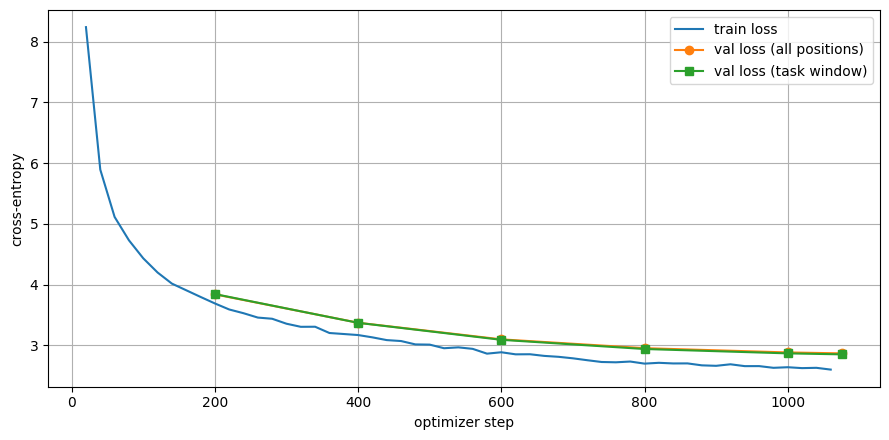

In [15]:
import matplotlib.pyplot as plt
hist = json.load(open(HISTORY_PATH))
tr = [(h["step"], h["train_loss"]) for h in hist if "train_loss" in h]
va = [(h["step"], h["val_loss"]) for h in hist if "val_loss" in h]
vt = [(h["step"], h["val_task_loss"]) for h in hist if "val_task_loss" in h]
plt.figure(figsize=(9, 4.5))
plt.plot(*zip(*tr), label="train loss")
plt.plot(*zip(*va), marker="o", label="val loss (all positions)")
plt.plot(*zip(*vt), marker="s", label="val loss (task window)")
plt.xlabel("optimizer step"); plt.ylabel("cross-entropy"); plt.grid(True); plt.legend(); plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/loss_curve.png", dpi=150); plt.show()

## 9. Generation (batched, constant-state decoding)
The prompt is **left-padded** and read once in parallel form (the SSM layers build their final state, the attention layers fill their KV-cache).
Each new token then costs one recurrent SSM update per Mamba layer (constant time and memory) plus a cached attention step in the 6 attention layers.
Same decoding controls as the earlier attempts: temperature, top-p, repetition penalty on **generated** tokens only, EOS banned so every output reaches 128 words.

In [16]:
EOS_ID = tokenizer.eos_id
best = torch.load(CKPT_BEST, map_location=device, weights_only=False)
model.load_state_dict(best["model"]); model.eval()
print("loaded best checkpoint from step", best["step"])

@torch.no_grad()
def generate(prompt_ids, max_new=MAX_NEW_TOKENS, temperature=0.3, top_p=0.9, rep_penalty=1.1):
    B, L = len(prompt_ids), max(len(p) for p in prompt_ids)
    idx = torch.full((B, L), EOS_ID, dtype=torch.long)
    valid = torch.zeros(B, L, dtype=torch.bool)
    for i, p in enumerate(prompt_ids):                       # LEFT-pad so every prompt ends at the last column
        idx[i, L - len(p):] = torch.tensor(p); valid[i, L - len(p):] = True
    idx, valid = idx.to(device), valid.to(device)
    pos = valid.sum(1)                                       # position of the next token for each row
    seen = torch.zeros(B, tokenizer.vocab_size, dtype=torch.bool, device=device)
    out = []
    with torch.autocast(device, dtype=torch.float16, enabled=device == "cuda"):
        logits, _, caches = model(idx, valid=valid, want_cache=True, last_only=True)     # parallel prefill
        key_valid = valid
        for t in range(max_new):
            lg = logits[:, -1].float()
            lg[:, EOS_ID] = -float("inf")
            if rep_penalty != 1.0:
                lg = torch.where(seen, torch.where(lg > 0, lg / rep_penalty, lg * rep_penalty), lg)
            if temperature <= 0:
                nxt = lg.argmax(-1)
            else:
                probs = F.softmax(lg / temperature, -1)
                sp, si = probs.sort(-1, descending=True)
                drop = (sp.cumsum(-1) - sp) > top_p
                sp = sp.masked_fill(drop, 0.0)
                nxt = si.gather(1, torch.multinomial(sp / sp.sum(-1, keepdim=True), 1)).squeeze(1)
            out.append(nxt); seen[torch.arange(B, device=device), nxt] = True
            if t == max_new - 1: break
            key_valid = torch.cat([key_valid, torch.ones(B, 1, dtype=torch.bool, device=device)], 1)
            logits, caches = model.step(nxt[:, None], pos, key_valid[:, None, None, :], caches)   # recurrent step
            pos = pos + 1
    return torch.stack(out, 1).tolist()

PROMPT_TOKEN_CAP = CONTEXT - MAX_NEW_TOKENS                   # attention RoPE table covers CONTEXT positions

def continue_texts(prompts, batch_size=16, **gen_kw):
    """prompts: raw strings -> list of continuations (exactly <=128 words each)."""
    enc = [tokenizer.encode(normalize_text(p, KEEP_NEWLINES))[-PROMPT_TOKEN_CAP:] for p in prompts]
    order = sorted(range(len(enc)), key=lambda i: len(enc[i]))      # similar lengths -> less padding
    results = [None] * len(enc)
    for s in range(0, len(order), batch_size):
        idx = order[s:s + batch_size]
        for i, toks in zip(idx, generate([enc[i] for i in idx], **gen_kw)):
            results[i] = " ".join(tokenizer.decode(toks).split()[:TARGET_WORDS])
    return results

lens = [len(tokenizer.encode(normalize_text(p, KEEP_NEWLINES))) for p in test_prompts_raw[:300]]
print(f"test prompt tokens: median {np.median(lens):.0f}, p99 {np.percentile(lens, 99):.0f}, "
      f"cap {PROMPT_TOKEN_CAP} -> {'OK' if np.percentile(lens, 99) <= PROMPT_TOKEN_CAP else 'prompts get truncated (keeps the LAST tokens)'}")

loaded best checkpoint from step 1076
test prompt tokens: median 609, p99 712, cap 1024 -> OK


## 10. Local validation and decoding sweep
Identical to attempt 2 so the three models are scored on the **same local prompts** with the **same metric**: held-out documents cut into 512-word prompts and 128-word references; BERTScore F1 (primary) via the `bert-score` package when available, ROUGE-L always.
Confirm the final decoding choice with the organisers' evaluation script, since its exact BERTScore settings may differ.

In [17]:
def rouge_l_f1(hyp, ref):
    h, r = hyp.split(), ref.split()
    if not h or not r: return 0.0
    prev = [0] * (len(r) + 1)
    for i in range(1, len(h) + 1):
        cur = [0] * (len(r) + 1)
        for j in range(1, len(r) + 1):
            cur[j] = prev[j - 1] + 1 if h[i - 1] == r[j - 1] else max(prev[j], cur[j - 1])
        prev = cur
    l = prev[-1]
    return 0.0 if l == 0 else 2 * (l / len(h)) * (l / len(r)) / ((l / len(h)) + (l / len(r)))

bert_scorer = None
if USE_BERTSCORE and not DEBUG:
    try:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "bert-score"], check=False)
        from bert_score import BERTScorer
        bert_scorer = BERTScorer(lang="en", device=device)
        print("BERTScore ready")
    except Exception as ex:
        print("BERTScore unavailable, falling back to ROUGE-L:", repr(ex)[:200])

def bertscore_f1(hyps, refs):
    _, _, f = bert_scorer.score(hyps, refs, batch_size=16)
    return float(f.mean())

def build_local_eval(n=96):
    items = []
    for line in open(f"{DATA_DIR}/val.jsonl", encoding="utf-8"):
        w = json.loads(line)["text"].split()
        if len(w) >= PROMPT_WORDS + TARGET_WORDS + 50:
            s = random.Random(len(items)).randint(0, len(w) - PROMPT_WORDS - TARGET_WORDS)
            items.append((" ".join(w[s:s + PROMPT_WORDS]),
                          " ".join(w[s + PROMPT_WORDS:s + PROMPT_WORDS + TARGET_WORDS])))
    random.Random(SEED).shuffle(items)
    return items[:n]

local = build_local_eval()
l_prompts, l_refs = [p for p, _ in local], [r for _, r in local]
DECODING = {
    "greedy_rep1.10": dict(temperature=0.0, rep_penalty=1.10),
    "greedy_rep1.20": dict(temperature=0.0, rep_penalty=1.20),
    "t0.3_p0.9_rep1.10": dict(temperature=0.3, top_p=0.9, rep_penalty=1.10),
    "t0.7_p0.9_rep1.10": dict(temperature=0.7, top_p=0.9, rep_penalty=1.10),
}
scores, rouges = {}, {}
for name, kw in DECODING.items():
    t0 = time.time()
    hyps = continue_texts(l_prompts, **kw)
    rouges[name] = float(np.mean([rouge_l_f1(h, r) for h, r in zip(hyps, l_refs)]))
    scores[name] = bertscore_f1(hyps, l_refs) if bert_scorer is not None else rouges[name]
    print(f"{name:20s} {'BERTScore F1' if bert_scorer is not None else 'ROUGE-L F1'} {scores[name]:.4f} "
          f"| ROUGE-L {rouges[name]:.4f} | {time.time() - t0:.0f}s")
    if name == list(DECODING)[0]:
        print("  sample:", hyps[0][:300])
FINAL_DECODING = max(scores, key=scores.get)
print("selected decoding:", FINAL_DECODING)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 2.4 MB/s eta 0:00:00


config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.42GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.bias        | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BERTScore ready
greedy_rep1.10       BERTScore F1 0.8259 | ROUGE-L 0.1991 | 41s
  sample: letter is not in the nature of a letter. The respondent has been given the benefit of the said letter. It is true that the respondent has been denied the benefit of the said letter. In fact, he has been given the benefit of the said letter. He has also stated that he was not given any opportunity to
greedy_rep1.20       BERTScore F1 0.8306 | ROUGE-L 0.1927 | 39s
t0.3_p0.9_rep1.10    BERTScore F1 0.8305 | ROUGE-L 0.2007 | 40s
t0.7_p0.9_rep1.10    BERTScore F1 0.8324 | ROUGE-L 0.1972 | 40s
selected decoding: t0.7_p0.9_rep1.10


## 11. Official test inference -> `prediction.json` -> `submission.zip`

In [18]:
test_ids = list(test_data.keys())
t0 = time.time()
final_texts = continue_texts([test_data[i]["text"] for i in test_ids], **DECODING[FINAL_DECODING])
print(f"generated {len(final_texts)} continuations in {(time.time() - t0) / 60:.1f} min")

predictions = {str(i): {"text": t} for i, t in zip(test_ids, final_texts)}
with open(PREDICTION_PATH, "w", encoding="utf-8") as f:
    json.dump(predictions, f, ensure_ascii=False, indent=2)

with zipfile.ZipFile(SUBMISSION_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as z:
    z.write(PREDICTION_PATH, arcname="prediction.json")        # must sit at the archive root

wc = [len(v["text"].split()) for v in predictions.values()]
assert len(predictions) == len(test_data) and min(wc) > 0
print(f"prediction.json: {len(predictions)} items | words per item: min {min(wc)}, mean {np.mean(wc):.1f}, max {max(wc)}")
print("submission archive:", SUBMISSION_ZIP, "->", zipfile.ZipFile(SUBMISSION_ZIP).namelist())

generated 1000 continuations in 6.2 min
prediction.json: 1000 items | words per item: min 10, mean 127.8, max 128
submission archive: /kaggle/working/cs781_phase1_hybrid/submission.zip -> ['prediction.json']


## 12. Experiment record (fill in for the report and viva)

| Run | Architecture | Params | Tokens seen | Overall val loss | Task-window val loss (610 -> 192) | Local BERTScore F1 | Local ROUGE-L | Codabench | Notes |
|---|---|---|---|---|---|---|---|---|---|
| Attempt 1 | Decoder-only (RoPE, GQA, SwiGLU) | 121M | ~150M | | | | | | |
| Attempt 2 | Encoder-decoder (T5-style) | 124M | ~150M | n/a | | | | | 75% continuation + 25% span corruption |
| **Attempt 3** | **Mamba-2 / attention hybrid (this notebook)** | 128M | see benchmark | | | | | | 18 SSM + 6 attention layers |

Both validation columns are computed on the same held-out documents and the same 610 -> 192 window, so attempts 1-3 are directly comparable on the task-window loss.

Ablations worth running (change one thing at a time): `PATTERN` in {`"M"*30` (pure SSM), `"MMMMMMMA"*3`, `"MMMA"*6`, `"MA"*12`}; `D_STATE` in {32, 64, 128}; `SSD_CHUNK` in {64, 128} (speed/memory only); decoding settings.